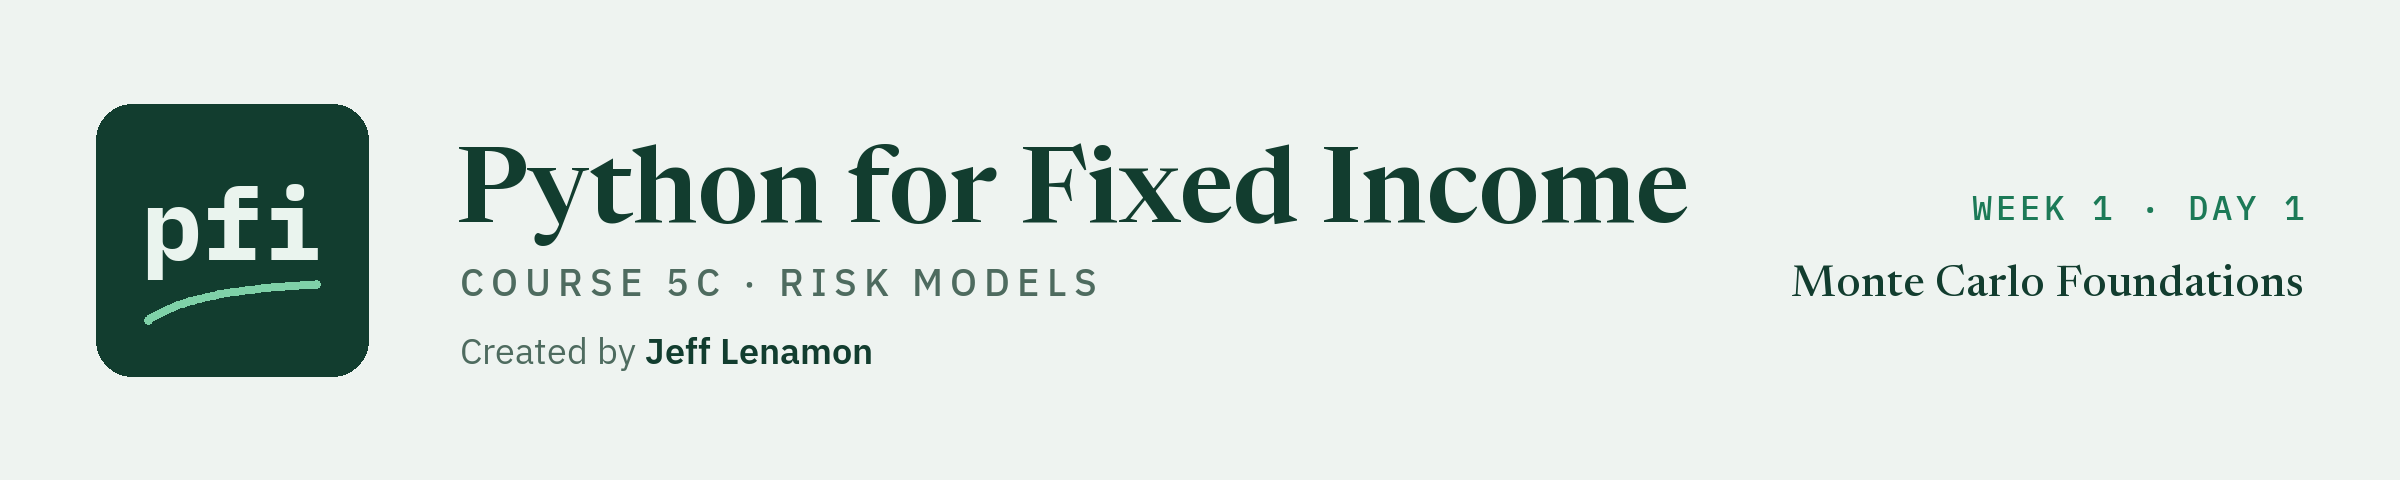

# Monte Carlo Foundations

Week 1, Day 1. Course 5C builds risk models: losses that have not happened, defaults, unusual data, and drift. Today: Monte Carlo, the method under the first three days. Draw, average, and say how far the average can be from the truth.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course5c_risk_models/week1/day1/01_monte_carlo_foundations.ipynb)

Course 5 fitted models that score and classify; Course 5B modelled one dated series at a time. This course builds the models a risk desk runs: a loss distribution, a default curve, a screen for unusual data, and a check that a model's inputs still look like the data it was fitted on. Week 1 is simulation and default; week 2 is the unusual and the drifting.

Monte Carlo comes first because the next two days stand on it. When a loss depends on many uncertain things at once, there is often no formula for its distribution, but there is always a way to draw it: simulate the uncertain things many times, compute the loss each time, and read the distribution off the results. Today does that on a case whose exact answer is known, so every simulated number can be checked.

* **The book is synthetic.** `holdings.csv` is the course's book of 200 invented bonds. Today uses one of them: the largest BB holding.
* **The inputs are chosen for the lesson.** A 2 percent default chance a year and a 60 percent loss given default are round numbers picked so the arithmetic is easy to follow. They are not an estimate for this bond, its issuer, or any real company. From day 3, default rates come from the course's synthetic cohort.
* **Names.** A simulated number is "a simulated loss" or "a Monte Carlo mean, with its standard error". It is never a forecast of a loss, and nothing here is a view on any bond.

Today you will:

1. Simulate one bond's credit loss year by year, and compare the average with the exact expected loss.
2. Seed numpy's generator, reproduce every draw, and make independent streams with `spawn`.
3. Watch the average settle as trials are added, and measure how far off it can be: the standard error (`mc_mean`).
4. Draw from the normal, Student's t, lognormal, and beta distributions, and read every setting.
5. Count defaults among 50 independent bonds, and check the simulation against the exact binomial answer.
6. Spend the same number of draws more wisely with antithetic pairs (`antithetic_normals`), and see when that fails.
7. Say how many trials a stated precision needs (`trials_needed`), and check how often the interval really holds the truth.

Q. Set up today's work folder: the thread settings, the seed, the book and the rating scale, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course5c_risk_models/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, scipy, statsmodels, or scikit-learn is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course5c_risk_models/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5c_01_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["holdings.csv", "ratings.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, scikit-learn 1.9.1, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5c_01_ef88b9nr, in your temp folder
Data files from the data folder of the course repo: holdings.csv, ratings.csv
SEED = 42


The setup cell is the same in every Course 5C notebook, and it is Course 5B's with this course's libraries. It sets the two thread variables before numpy, pandas, scipy, statsmodels, or scikit-learn is imported, so every run adds its numbers in the same order and prints the same last digits. It stops with the install line if a library is missing, prints the versions the saved outputs came from, sets `SEED = 42`, makes a fresh work folder outside the repo, and copies today's data files into it.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `riskkit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [4]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [5]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* `mlkit.py` is Course 4's complete module, unchanged. Today starts a new module, `riskkit`, which imports it: from day 5 its past-only check guards the hazard models.
* `plotkit.py` is the series' chart and table helpers, also unchanged. It stays out of today's commits.

## 1.1 One Bond's Loss in a Year

**How it works.** Monte Carlo answers a question about an average or a distribution by drawing it. Write down what is uncertain (here, whether the bond defaults this year) and how likely each outcome is (a 2 percent chance). Draw that outcome many times with a random number generator, compute the loss for each draw, and average. The average of many independent draws lands close to the true mean, and how close is something you can measure from the draws themselves (section 1.3). The settings that matter are the inputs, the number of trials, and the seed that fixes the draws. What comes out is a set of simulated losses: their mean, their spread, and their tail.

Q. Load the book and pick today's bond: the largest BB holding by market value.

In [6]:
# the book and the rating scale: every issuer and CUSIP in both files is invented
book = pd.read_csv("holdings.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")
book["bucket"] = book["rating"].map(ratings["bucket"])

# the bond for today: the book's largest BB holding by market value
bond = book[book["bucket"] == "BB"].sort_values("market_value", ascending=False).iloc[0]
print(f"{bond['issuer']} ({bond['cusip']}), rated {bond['rating']}: market value US${bond['market_value']:,.0f}")

Lorvebran Paper (99076YAC0), rated BB: market value US$5,287,462


* Lorvebran Paper is an invented issuer; the CUSIP starts with 99, in the range reserved for internal use, so it can be no real security.

Q. Set the two inputs, and compute the exact expected loss and the standard deviation of one year's loss.

In [7]:
# two inputs chosen for the lesson, not an estimate for this or any issuer
PD = 0.02     # the chance of default within one year: 2 percent
LGD = 0.60    # the share of the exposure lost if it defaults: 60 percent
EAD = float(bond["market_value"])   # the exposure at default, in US$: today's market value

# the exact answers, which the simulation has to find on its own
expected_loss = PD * LGD * EAD
sd_one_trial = np.sqrt(PD * (1 - PD)) * LGD * EAD
print(f"expected loss: US${expected_loss:,.2f}")
print(f"standard deviation of one year's loss: US${sd_one_trial:,.2f}")

expected loss: US$63,449.55
standard deviation of one year's loss: US$444,146.85


* The expected loss is PD x LGD x EAD: 0.02 x 0.60 x US$5,287,462 = US$63,450. In any one year the loss is either US$0 or US$3,172,478, never US$63,450: the expected loss is an average over many years, which is exactly what a simulation can count.
* The standard deviation of one year's loss is US$444,147, about 7 times the mean. A rare, large loss has a spread far bigger than its mean, and that is why a simulation of it needs many trials.

Q. Simulate ten years. In each, draw a uniform number between 0 and 1; the bond defaults when the number is below PD.

In [8]:
# ten simulated years: draw a uniform number for each; below PD means the bond defaulted that year
rng = np.random.default_rng(SEED)
uniforms = rng.random(10)
defaulted = uniforms < PD
losses_10 = np.where(defaulted, LGD * EAD, 0.0)
for year, (u, loss) in enumerate(zip(uniforms, losses_10), start=1):
    print(f"year {year:2d}: uniform {u:.4f}, loss US${loss:,.0f}")
print(f"average loss over 10 years: US${losses_10.mean():,.0f}")

year  1: uniform 0.7740, loss US$0
year  2: uniform 0.4389, loss US$0
year  3: uniform 0.8586, loss US$0
year  4: uniform 0.6974, loss US$0
year  5: uniform 0.0942, loss US$0
year  6: uniform 0.9756, loss US$0
year  7: uniform 0.7611, loss US$0
year  8: uniform 0.7861, loss US$0
year  9: uniform 0.1281, loss US$0
year 10: uniform 0.4504, loss US$0
average loss over 10 years: US$0


* A uniform number lands below 0.02 two times in a hundred, so "below PD" happens with exactly the chance PD. Ten years gave 0 defaults, so ten trials say almost nothing about a 2 percent event.

Q. Simulate 100,000 years.

In [9]:
# 100,000 simulated years from a fresh generator with the same seed
rng = np.random.default_rng(SEED)
u_100k = rng.random(100_000)
losses = np.where(u_100k < PD, LGD * EAD, 0.0)
print(f"years with a default: {int((losses > 0).sum()):,} of {len(losses):,}")
print(f"average loss: US${losses.mean():,.2f}; exact expected loss: US${expected_loss:,.2f}")

years with a default: 1,991 of 100,000
average loss: US$63,164.03; exact expected loss: US$63,449.55


* 1,991 defaults in 100,000 years, and an average loss of US$63,164 against the exact US$63,450. Close, not equal: section 1.3 says how close to expect.

In [10]:
# the inputs and the two answers in one table
summary = pd.DataFrame({
    "value": [bond["issuer"], bond["rating"], f"US${EAD:,.0f}", f"{PD:.0%}", f"{LGD:.0%}", f"US${LGD * EAD:,.0f}",
              f"US${expected_loss:,.2f}", f"US${losses.mean():,.2f}"],
}, index=pd.Index(["issuer (invented)", "rating", "exposure at default (market value)", "default chance a year (input)",
                   "loss given default (input)", "loss in a year with a default", "expected loss, exact",
                   "mean of 100,000 simulated years"], name="item"))
plotkit.styled(summary, [], "Today's bond: the two inputs chosen for the lesson, the exact expected loss, and the simulated mean")

,value
item,
issuer (invented),Lorvebran Paper
rating,BB
exposure at default (market value),"US$5,287,462"
default chance a year (input),2%
loss given default (input),60%
loss in a year with a default,"US$3,172,478"
"expected loss, exact","US$63,449.55"
"mean of 100,000 simulated years","US$63,164.03"


## 1.2 Random Numbers and Seeds

**How it works.** A computer's random numbers come from a generator: an algorithm that turns a starting number, the **seed**, into a long stream of numbers that pass every test of randomness while being completely determined by the seed. numpy's `default_rng(seed)` makes such a generator (PCG64). Each draw moves it along its stream, so two generators from the same seed give the same draws in the same order. The settings are the seed, and how you split one stream into several. What comes out is reproducibility: rerun the notebook and every simulated loss is the same.

Older code uses numpy's global functions, `np.random.seed(...)` then `np.random.rand(...)`: one hidden generator shared by every line of code that touches it, so a draw anywhere changes the numbers everywhere after it. This course never uses them, and its checks refuse them.

Q. Do two generators made from the same seed draw the same numbers? How do you get two streams that do not overlap?

In [11]:
# the same seed gives the same draws, every run, on every machine with this numpy
first = np.random.default_rng(SEED).random(3)
second = np.random.default_rng(SEED).random(3)
print(f"two generators from SEED: {first.round(6).tolist()} and {second.round(6).tolist()}; same: {np.array_equal(first, second)}")

# spawn makes independent child generators from one seeded parent: one stream per experiment, still reproducible
child_a, child_b = np.random.default_rng(SEED).spawn(2)
print(f"child a: {child_a.random(3).round(6).tolist()}")
print(f"child b: {child_b.random(3).round(6).tolist()}")

two generators from SEED: [0.773956, 0.438878, 0.858598] and [0.773956, 0.438878, 0.858598]; same: True
child a: [0.916744, 0.910987, 0.876593]
child b: [0.467491, 0.046449, 0.59551]


* Same seed, same draws, every time. That is why every simulation cell today starts its own generator from `SEED`: its numbers do not depend on which cells ran before it.
* `spawn(2)` makes two child generators from one parent. Their streams are independent of each other and still fixed by `SEED`: the right way to run two experiments side by side, as section 1.6 does.

Q. Turn uniform draws into normal draws by the inverse of the normal distribution, and compare with numpy's own normal draws.

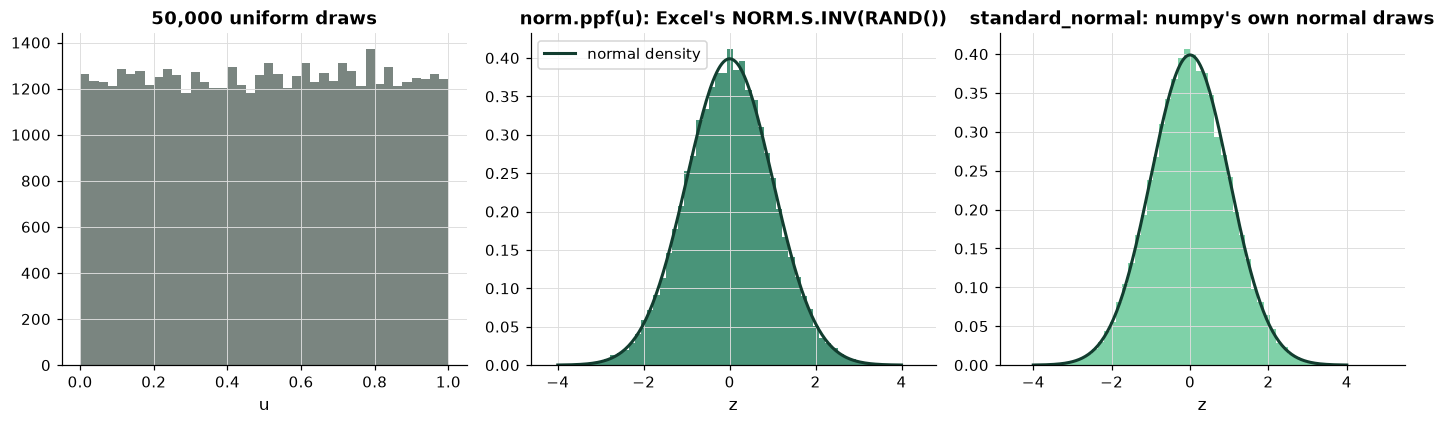

In [12]:
from scipy.stats import norm

# the inverse transform: a uniform u becomes the normal value with probability u below it
rng = np.random.default_rng(SEED)
u = rng.random(50_000)
from_uniform = norm.ppf(u)
direct = np.random.default_rng(SEED).standard_normal(50_000)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].hist(u, bins=40, color=plotkit.GREY)
axes[0].set_title("50,000 uniform draws")
axes[0].set_xlabel("u")
axes[1].hist(from_uniform, bins=60, density=True, color=plotkit.GREEN, alpha=0.8)
grid = np.linspace(-4, 4, 200)
axes[1].plot(grid, norm.pdf(grid), color=plotkit.GREEN_DARK, linewidth=2, label="normal density")
axes[1].set_title("norm.ppf(u): Excel's NORM.S.INV(RAND())")
axes[1].legend(loc="upper left")
axes[2].hist(direct, bins=60, density=True, color=plotkit.GREEN_LIGHT)
axes[2].plot(grid, norm.pdf(grid), color=plotkit.GREEN_DARK, linewidth=2)
axes[2].set_title("standard_normal: numpy's own normal draws")
for ax in axes[1:]:
    ax.set_xlabel("z")
fig.tight_layout()
plt.show()

* How to read it: the left panel is flat (every value between 0 and 1 equally likely). Pushed through the inverse of the normal distribution, the same draws make the bell in the middle, on top of the exact density. numpy's `standard_normal` makes the bell on the right with a faster method and different draws: both are standard normal, neither is "the" normal sample. Excel makes normal draws the middle panel's way, as the Excel section shows.

## 1.3 The Law of Large Numbers and the Standard Error

**How it works.** The mean of n independent draws lands, on average, on the true mean (the law of large numbers), and its typical distance from the truth is the **standard error**: the standard deviation of one draw divided by the square root of n. Both pieces come from the draws themselves, so a simulation reports its own precision. The setting is n: four times the trials halve the standard error, a hundred times cut it by ten. What comes out is an estimate with an error band, usually the mean plus and minus 1.96 standard errors, which holds the true mean in about 95 percent of runs when n is large enough (section 1.7 checks "large enough").

Q. Write `riskkit.py` with `mc_mean` and `trials_needed`. Read the docstrings first.

In [13]:
%%writefile riskkit.py
"""riskkit: risk models for a bond desk, built day by day in Course 5C.

Conventions, stated once:
- Money is in US$. Rate and spread moves are in bp. A default probability is a fraction a year: 0.02 is 2 percent.
- A loss is a positive number of US$. P&L is positive for a gain.
- Every random draw comes from a numpy Generator the caller passes in as rng. Nothing here seeds a generator or
  uses the legacy np.random functions, so one seed at the top of a notebook decides every draw.
- The inputs are the course's synthetic book, its synthetic cohort, or past data. Nothing here describes a real
  security or a real issuer.
"""
import math

import numpy as np
from scipy.stats import norm

import mlkit  # noqa: F401  (the past-only checks, used from day 5)


def mc_mean(draws) -> tuple[float, float]:
    """The Monte Carlo estimate of a mean, and its standard error.

    Input: draws, a 1-D array of independent trial outcomes: at least 2, none of them NaN.
    Output: (mean, standard error). The standard error is the sample standard deviation (ddof=1) over the
    square root of the number of draws: how far the mean of this many draws typically lands from the true mean.
    Raises ValueError for fewer than 2 draws, more than one dimension, or a NaN.
    """
    values = np.asarray(draws, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("draws must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("draws hold a NaN")
    return float(values.mean()), float(values.std(ddof=1) / math.sqrt(len(values)))


def trials_needed(sd: float, half_width: float, confidence: float = 0.95) -> int:
    """How many independent trials put a Monte Carlo mean within half_width of the true mean, at this confidence.

    n = ceil((z * sd / half_width) ** 2), with z the two-sided normal quantile (1.96 at 0.95).
    Inputs: sd, the standard deviation of one trial, and half_width, in the same unit, both above 0; confidence
    strictly between 0 and 1.
    Output: the number of trials, a whole number.
    Raises ValueError for an sd or half_width that is not above 0, or a confidence outside (0, 1).
    """
    if sd <= 0 or half_width <= 0:
        raise ValueError("sd and half_width must be above 0")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be between 0 and 1")
    z = norm.ppf(0.5 + confidence / 2)
    return math.ceil((z * sd / half_width) ** 2)

Writing riskkit.py


* The module docstring states the course's conventions once: US$, bp, default chances as fractions a year, losses as positive numbers, and every draw from a generator passed in by the caller, so one seed decides everything.
* `mc_mean` refuses fewer than two draws (a standard deviation needs two) and a NaN, which would make every number after it NaN without a word.
* `trials_needed` turns the standard error around: for a stated half-width and confidence it solves for n.

Q. Write the tests: hand-checked values, the refusals, and a mean that lands near a known answer.

In [14]:
%%writefile test_riskkit.py
"""Tests for riskkit.py. Small seeded arrays only; no data file is read."""
import math

import numpy as np
import pytest

import riskkit


def test_mc_mean_hand():
    # mean 2.5; sample standard deviation sqrt(5/3); standard error that over sqrt(4)
    mean, se = riskkit.mc_mean([1.0, 2.0, 3.0, 4.0])
    assert mean == 2.5
    assert se == pytest.approx(math.sqrt(5 / 3) / 2, rel=1e-12)


def test_mc_mean_refuses():
    with pytest.raises(ValueError, match="at least 2"):
        riskkit.mc_mean([1.0])
    with pytest.raises(ValueError, match="NaN"):
        riskkit.mc_mean([1.0, float("nan"), 3.0])


def test_mc_mean_covers_a_known_mean():
    # 2 percent default, US$600,000 lost: the true mean is US$12,000; 40,000 draws land within 4 standard errors
    rng = np.random.default_rng(42)
    losses = np.where(rng.random(40_000) < 0.02, 600_000.0, 0.0)
    mean, se = riskkit.mc_mean(losses)
    assert abs(mean - 12_000.0) < 4 * se


def test_trials_needed_hand():
    # z at 95 percent is 1.959964; (1.959964 * 10 / 1) ** 2 = 384.15, so 385 trials
    assert riskkit.trials_needed(10.0, 1.0) == 385
    # halving the half-width takes four times the trials, give or take the rounding up
    assert riskkit.trials_needed(10.0, 0.5) == 1_537
    with pytest.raises(ValueError, match="above 0"):
        riskkit.trials_needed(10.0, 0.0)
    with pytest.raises(ValueError, match="between 0 and 1"):
        riskkit.trials_needed(10.0, 1.0, confidence=1.0)

Writing test_riskkit.py


* `test_mc_mean_covers_a_known_mean` simulates the same kind of loss with its own seed and asserts that the mean lands within 4 standard errors of the exact value. A test of a simulation tests a band, never an exact number.

Q. Import the module and run the tests.

In [15]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import riskkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(riskkit)

# the functions defined in riskkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(riskkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "riskkit" and not name.startswith("_")]
print(f"riskkit functions: {functions}")

riskkit functions: ['mc_mean', 'trials_needed']


In [16]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....                                                                     [100%]
4 passed in 1.67s



* `4 passed`. The tests read no data file: they run in a few seconds on any machine.

Q. How far is the mean from the exact expected loss after 100, 1,000, 10,000, and 100,000 trials, and how far should it be?

In [17]:
# the running mean after each trial, and its band of 1.96 standard errors at a few sample sizes
running = np.cumsum(losses) / np.arange(1, len(losses) + 1)
rows = []
for n in [100, 1_000, 10_000, 100_000]:
    mean, se = riskkit.mc_mean(losses[:n])
    rows.append({"trials": n, "mean loss (US$)": mean, "standard error (US$)": se,
                 "error against the exact (US$)": mean - expected_loss, "inside 1.96 SE": abs(mean - expected_loss) <= 1.96 * se})
convergence = pd.DataFrame(rows).set_index("trials")
print(convergence.round(0).to_string())

        mean loss (US$)  standard error (US$)  error against the exact (US$)  inside 1.96 SE
trials                                                                                      
100             31725.0               31725.0                       -31725.0            True
1000            63450.0               14052.0                            0.0            True
10000           59325.0                4298.0                        -4124.0            True
100000          63164.0                1401.0                         -286.0            True


In [18]:
plotkit.styled(convergence.drop(columns="inside 1.96 SE"), ["standard error (US$)"],
               "One bond's simulated loss: the mean after n trials, its standard error, and its error against the exact "
               "expected loss", higher_is_better=False, fmt="{:,.0f}")

,mean loss (US$),standard error (US$),error against the exact (US$)
trials,,,
100,"31,725","31,725","-31,725"
1000,"63,450","14,052",0
10000,"59,325","4,298","-4,124"
100000,"63,164","1,401",-286


* After 100 trials the mean is US$31,725: one default in 100 years, worth US$3,172,478 / 100. After 100,000 it is US$63,164, with a standard error of US$1,401. At every size the error against the exact answer is inside 1.96 standard errors.
* From 1,000 to 100,000 trials the standard error falls by a factor of 10.0: a hundred times the work for ten times the precision. That square root is the price of Monte Carlo.

Q. Draw the running mean after every trial, with its band of 1.96 standard errors.

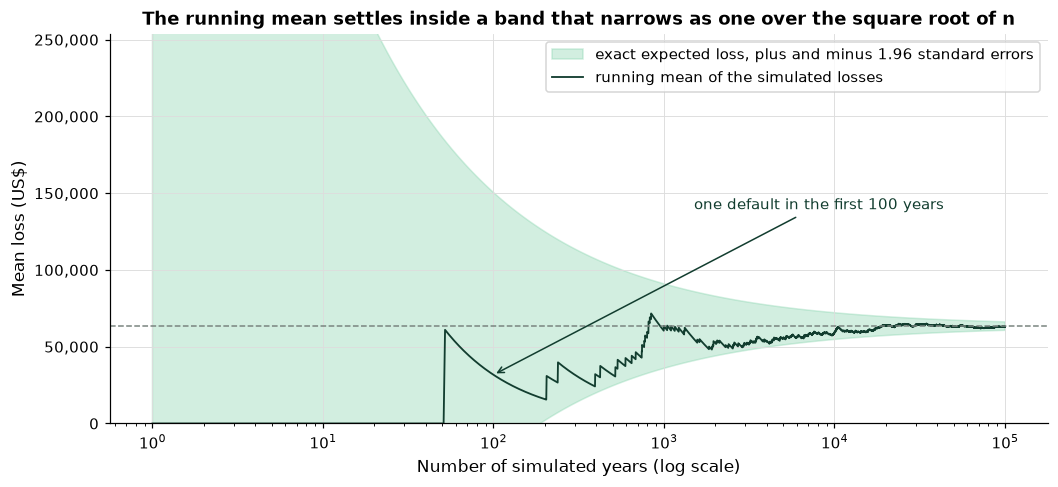

In [19]:
# the band uses the exact standard deviation of one trial, so it shows where the mean should be after n trials
n = np.arange(1, len(losses) + 1)
band = 1.96 * sd_one_trial / np.sqrt(n)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(n, expected_loss - band, expected_loss + band, color=plotkit.GREEN_LIGHT, alpha=0.35,
                label="exact expected loss, plus and minus 1.96 standard errors")
ax.plot(n, running, color=plotkit.GREEN_DARK, linewidth=1.2, label="running mean of the simulated losses")
ax.axhline(expected_loss, color=plotkit.GREY, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_ylim(0, 4 * expected_loss)
ax.set_xlabel("Number of simulated years (log scale)")
ax.set_ylabel("Mean loss (US$)")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.annotate("one default in the first 100 years", xy=(100, running[99]), xytext=(1_500, 2.2 * expected_loss),
            fontsize=10, color=plotkit.GREEN_DARK, arrowprops={"arrowstyle": "->", "color": plotkit.GREEN_DARK})
ax.set_title("The running mean settles inside a band that narrows as one over the square root of n")
ax.legend(loc="upper right")
plt.show()

* How to read it: the x axis is logarithmic, so each step right is ten times the trials. The mean jumps up at every default and drifts down between them; early on, each jump is large. The band narrows by a factor of about 3.2 per step (the square root of 10), and the mean stays inside it after the first few hundred years. A jump that leaves the band is not a bug: about one run in twenty does.

## 1.4 Distributions for Risk Inputs

**How it works.** A simulation is only as good as the distributions it draws from. A rate or spread shock is often drawn **normal**; real daily moves have fatter tails, which a **Student's t** gives, with its degrees of freedom (df) setting how fat. A quantity that cannot go below zero and has a long right tail, such as a spread level, is drawn **lognormal**. A share between 0 and 1, such as a recovery rate, is drawn **beta**. The settings are each distribution's parameters, and the one to look at first is whatever sets the tail, because risk lives in the tail. What comes out is a set of draws whose shape you chose, and should be able to defend.

Q. Read every setting of the Generator methods this course uses.

In [20]:
# the Generator methods used in this course, with what each setting does (numpy's own names)
generator_settings = pd.DataFrame([
    ("random(size)", "size", "how many uniform draws, each in [0, 1)", "default flags: uniform below PD"),
    ("standard_normal(size)", "size", "how many draws with mean 0 and standard deviation 1", "rate and spread shocks, the common factor of day 3"),
    ("normal(loc, scale, size)", "loc, scale", "the mean and the standard deviation", "a shock with its own scale"),
    ("standard_t(df, size)", "df", "degrees of freedom: lower means fatter tails; above 30 it is close to normal", "shocks with fat tails, day 2"),
    ("lognormal(mean, sigma, size)", "mean, sigma", "the mean and standard deviation of the log; sigma sets the skew", "a quantity that cannot go below zero"),
    ("beta(a, b, size)", "a, b", "two shapes on [0, 1]; mean a / (a + b); larger a + b means tighter", "recovery rates, day 3"),
    ("binomial(n, p, size)", "n, p", "the number of successes in n tries, each with chance p", "the count of defaults in a group"),
    ("spawn(n_children)", "n_children", "independent child generators from one parent", "one stream per experiment"),
], columns=["method", "settings", "what they control", "used for"]).set_index("method")

plotkit.styled(generator_settings, [], "numpy Generator methods used in Course 5C: each setting, what it controls, and where it is used")

,settings,what they control,used for
method,,,
random(size),size,"how many uniform draws, each in [0, 1)",default flags: uniform below PD
standard_normal(size),size,how many draws with mean 0 and standard deviation 1,"rate and spread shocks, the common factor of day 3"
"normal(loc, scale, size)","loc, scale",the mean and the standard deviation,a shock with its own scale
"standard_t(df, size)",df,degrees of freedom: lower means fatter tails; above 30 it is close to normal,"shocks with fat tails, day 2"
"lognormal(mean, sigma, size)","mean, sigma",the mean and standard deviation of the log; sigma sets the skew,a quantity that cannot go below zero
"beta(a, b, size)","a, b","two shapes on [0, 1]; mean a / (a + b); larger a + b means tighter","recovery rates, day 3"
"binomial(n, p, size)","n, p","the number of successes in n tries, each with chance p",the count of defaults in a group
spawn(n_children),n_children,independent child generators from one parent,one stream per experiment


* Every method takes `size`, how many draws. The settings that change a risk number are the ones that set a tail: `df` for the t, `sigma` for the lognormal, and `a + b` for the beta, as the panels below show.

Q. Draw each distribution with one setting changed per panel.

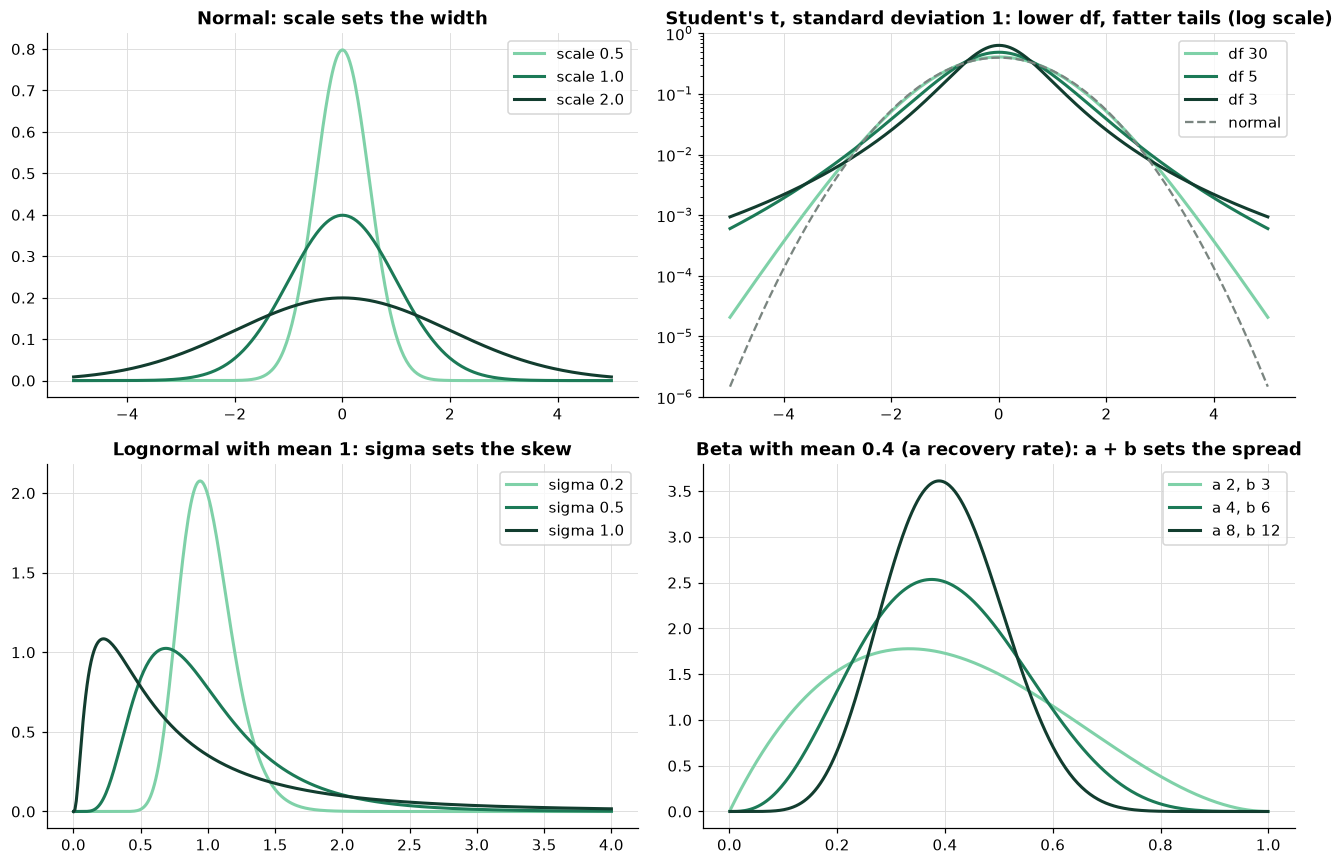

In [21]:
from scipy.stats import beta as beta_dist, lognorm, t as t_dist

grid = np.linspace(-5, 5, 400)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
shades = [plotkit.GREEN_LIGHT, plotkit.GREEN, plotkit.GREEN_DARK]

# normal: the scale changes, the shape does not
for scale, colour in zip([0.5, 1.0, 2.0], shades):
    axes[0, 0].plot(grid, norm.pdf(grid, scale=scale), color=colour, linewidth=2, label=f"scale {scale}")
axes[0, 0].set_title("Normal: scale sets the width")

# Student's t scaled to a standard deviation of 1: lower df puts more weight in the tails
for df, colour in zip([30, 5, 3], shades):
    scale = np.sqrt((df - 2) / df)
    axes[0, 1].plot(grid, t_dist.pdf(grid, df, scale=scale), color=colour, linewidth=2, label=f"df {df}")
axes[0, 1].plot(grid, norm.pdf(grid), color=plotkit.GREY, linestyle="--", label="normal")
axes[0, 1].set_yscale("log")
axes[0, 1].set_ylim(1e-6, 1)
axes[0, 1].set_title("Student's t, standard deviation 1: lower df, fatter tails (log scale)")

# lognormal with mean 1: sigma sets the skew
x = np.linspace(0.001, 4, 400)
for sigma, colour in zip([0.2, 0.5, 1.0], shades):
    axes[1, 0].plot(x, lognorm.pdf(x, sigma, scale=np.exp(-sigma ** 2 / 2)), color=colour, linewidth=2, label=f"sigma {sigma}")
axes[1, 0].set_title("Lognormal with mean 1: sigma sets the skew")

# beta with mean 0.4: a larger a + b concentrates the draws
r = np.linspace(0.001, 0.999, 400)
for a, b, colour in zip([2, 4, 8], [3, 6, 12], shades):
    axes[1, 1].plot(r, beta_dist.pdf(r, a, b), color=colour, linewidth=2, label=f"a {a}, b {b}")
axes[1, 1].set_title("Beta with mean 0.4 (a recovery rate): a + b sets the spread")
for ax in axes.flat:
    ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

* How to read it: each panel changes one setting and keeps the rest. The normal keeps its shape at any scale. The t panel is on a log scale so the tails show: at 4 or 5 standard deviations the df 3 curve sits orders of magnitude above the normal. The lognormal never goes below zero, and a larger sigma piles the draws up on the left with a long tail to the right. The three betas all have mean 0.4; the one with a + b = 20 says "close to 40 percent", the one with a + b = 5 says "anywhere from 5 to 80 percent".

Q. How much fatter are the tails? Draw a million values from each, scaled to a standard deviation of 1, and count the share beyond 3 and 5 standard deviations.

In [22]:
# how often a draw lands beyond 3 standard deviations, each distribution scaled to a standard deviation of 1
rng = np.random.default_rng(SEED)
n = 1_000_000
tails = {"normal": rng.standard_normal(n)}
for df in [30, 5, 3]:
    # a Student's t with df degrees of freedom has variance df / (df - 2); divide by its square root
    tails[f"Student's t, df {df}"] = rng.standard_t(df, n) / np.sqrt(df / (df - 2))
tail_table = pd.DataFrame({
    "share beyond 3 sd": {name: float(np.mean(np.abs(x) > 3)) for name, x in tails.items()},
    "share beyond 5 sd": {name: float(np.mean(np.abs(x) > 5)) for name, x in tails.items()},
})
tail_table["times the normal's share beyond 3 sd"] = tail_table["share beyond 3 sd"] / tail_table.loc["normal", "share beyond 3 sd"]
print(tail_table.to_string())

                    share beyond 3 sd  share beyond 5 sd  times the normal's share beyond 3 sd
normal                       0.002763           0.000001                              1.000000
Student's t, df 30           0.004048           0.000019                              1.465074
Student's t, df 5            0.011680           0.001368                              4.227289
Student's t, df 3            0.013657           0.003187                              4.942816


In [23]:
plotkit.styled(tail_table, [], "Share of a million draws beyond 3 and 5 standard deviations, each distribution scaled to "
               "a standard deviation of 1", fmt="{:.5f}")

,share beyond 3 sd,share beyond 5 sd,times the normal's share beyond 3 sd
normal,0.00276,0.00000,1.00000
"Student's t, df 30",0.00405,0.00002,1.46507
"Student's t, df 5",0.01168,0.00137,4.22729
"Student's t, df 3",0.01366,0.00319,4.94282


* The normal puts 0.0028 of its draws beyond 3 standard deviations; the t with df 3, at the same standard deviation, puts 4.9 times as many there. Two inputs with the same standard deviation can give very different tail losses. Day 2 measures this on the book's own daily moves.

## 1.5 Counting Defaults Among 50 Bonds

**How it works.** With many bonds, the question becomes "how many default this year?". If each of n bonds defaults with the same chance p, **independently** of the others, the count follows the binomial distribution, which has an exact formula. The simulation draws an n-by-years grid of uniforms, marks each cell below p, and counts the marks in each row. The settings are n, p, and independence. What comes out is the distribution of the count, and the simulated and exact versions must agree. Day 3 drops independence, and from then on only the simulation can answer.

Q. Simulate 100,000 years of 50 bonds, each with a 2 percent default chance, and compare the counts with the binomial.

In [24]:
from scipy.stats import binom

# 50 bonds, each with the same 2 percent default chance, defaulting independently; 100,000 simulated years
rng = np.random.default_rng(SEED)
n_bonds, n_years = 50, 100_000
counts = (rng.random((n_years, n_bonds)) < PD).sum(axis=1)

# the exact chance of k defaults: the binomial distribution with n = 50 and p = PD
k = np.arange(0, 8)
count_table = pd.DataFrame({
    "simulated share of years": [float(np.mean(counts == j)) for j in k],
    "exact (binomial)": binom.pmf(k, n_bonds, PD),
}, index=pd.Index(k, name="defaults in the year"))
count_table["gap"] = count_table["simulated share of years"] - count_table["exact (binomial)"]
p4_sim, p4_exact = float(np.mean(counts >= 4)), float(binom.sf(3, n_bonds, PD))
print(f"at least 4 defaults: simulated {p4_sim:.4f}, exact {p4_exact:.4f}")

at least 4 defaults: simulated 0.0167, exact 0.0178


In [25]:
plotkit.styled(count_table, [], "Defaults in a year among 50 independent bonds at a 2 percent chance each: simulated against exact",
               fmt="{:.4f}")

,simulated share of years,exact (binomial),gap
defaults in the year,,,
0,0.3639,0.3642,-0.0003
1,0.3715,0.3716,-0.0001
2,0.1873,0.1858,0.0015
3,0.0606,0.0607,-0.0000
4,0.0138,0.0145,-0.0008
5,0.0026,0.0027,-0.0002
6,0.0003,0.0004,-0.0001
7,0.0000,0.0001,-0.0000


* The two columns agree to within a few thousandths at every count. The most likely year has no default at all (36.4% of years); a year with 4 or more defaults happens 1.8% of the time exactly, 1.7% in the simulation.

Q. Draw the simulated shares beside the exact ones.

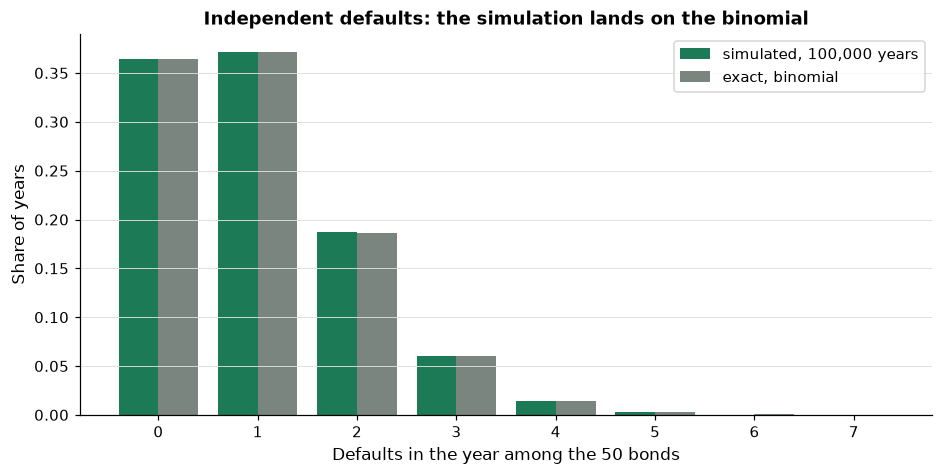

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.4
ax.bar(count_table.index - width / 2, count_table["simulated share of years"], width, color=plotkit.GREEN,
       label="simulated, 100,000 years")
ax.bar(count_table.index + width / 2, count_table["exact (binomial)"], width, color=plotkit.GREY, label="exact, binomial")
ax.set_xlabel("Defaults in the year among the 50 bonds")
ax.set_ylabel("Share of years")
ax.set_title("Independent defaults: the simulation lands on the binomial")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()

* Each pair of bars is the same height to the eye. Under independence, a bad year for one bond says nothing about the others, so a year with many defaults is very rare. Real defaults cluster: in a downturn many issuers struggle at once. Day 3 adds that and the right tail of this chart grows.

## 1.6 Antithetic Variates

**How it works.** A standard error falls only as one over the square root of n, so it pays to make each draw count. **Antithetic variates** draw half the normals, z, and use their mirror images, -z, for the other half. When the payoff rises steadily with z, a high draw is paired with a low one, their errors partly cancel, and the average of each pair is far less noisy than two independent draws. The setting is which payoff you apply it to: it helps a payoff that is monotone in z, and it does nothing, or harm, when the payoff is symmetric, because z and -z then give the same value. What comes out is the same mean with a smaller standard error, for the same number of draws.

Q. Add `antithetic_normals` to `riskkit.py`, with its tests.

In [27]:
%%writefile -a riskkit.py


def antithetic_normals(rng: np.random.Generator, n: int) -> np.ndarray:
    """n standard normal draws in antithetic pairs: n // 2 draws z, then their mirror images -z.

    Inputs: rng, a numpy Generator; n, a positive even number.
    Output: an array of n draws. Draw i and draw i + n // 2 are a pair (z and -z), so the draws' mean is 0 exactly.
    A pair is not two independent draws: average each pair before computing a standard error.
    Raises ValueError for an n that is odd or not above 0.
    """
    if n <= 0 or n % 2:
        raise ValueError("n must be a positive even number")
    half = rng.standard_normal(n // 2)
    return np.concatenate([half, -half])

Appending to riskkit.py


* The docstring warns that a pair is not two independent draws: the standard error must come from the pair averages, never from all n draws as if they were independent.

In [28]:
%%writefile -a test_riskkit.py


def test_antithetic_normals_pairs():
    draws = riskkit.antithetic_normals(np.random.default_rng(42), 10)
    assert len(draws) == 10
    assert np.array_equal(draws[5:], -draws[:5])
    assert draws.mean() == 0.0
    with pytest.raises(ValueError, match="even"):
        riskkit.antithetic_normals(np.random.default_rng(42), 7)


def test_antithetic_normals_same_seed_same_draws():
    first = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    second = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    assert np.array_equal(first, second)

Appending to test_riskkit.py


Q. Reload the module and run the tests.

In [29]:
# the file changed, so reload before using the new function
importlib.reload(riskkit)
print(f"antithetic_normals in riskkit: {hasattr(riskkit, 'antithetic_normals')}")

antithetic_normals in riskkit: True


In [30]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......                                                                   [100%]
6 passed in 1.69s



* `6 passed`: the 4 from section 1.3 and today's two new ones.

Q. Define two payoffs of a normal draw for today's bond: the P&L of a year's spread move, which rises steadily with z, and the size of a rate move, which is the same for z and -z.

In [31]:
# a spread move for the same bond over a year: its OAS times a lognormal relative change with mean 1
# SIGMA is an input chosen for the lesson; the move's mean is 0 bp exactly, so the true mean P&L is US$0
SIGMA = 0.40
OAS = float(bond["oas"])
SPREAD_DURATION = float(bond["spread_duration"])


def spread_pnl(z):
    """P&L in US$ of the bond for standard normal draws z: minus spread duration x market value x the move in bp."""
    move_bp = OAS * (np.exp(SIGMA * z - SIGMA ** 2 / 2) - 1)
    return -SPREAD_DURATION * EAD * move_bp / 10_000


def move_size_bp(z):
    """The size of a rate move in bp for standard normal draws z, with a 10 bp standard deviation: the same for z and -z."""
    return np.abs(10 * z)
print(f"OAS {OAS:.0f} bp, spread duration {SPREAD_DURATION:.3f}, sigma {SIGMA}")

OAS 229 bp, spread duration 6.240, sigma 0.4


* The spread move is the bond's OAS (229 bp) times a lognormal change with mean 1, so its mean is exactly 0 bp and the true mean P&L is US$0: a known answer to check against. `SIGMA = 0.40` is an input chosen for the lesson.

Q. Spend 20,000 normal draws two ways, plain and in antithetic pairs, on each payoff. Which has the smaller standard error?

In [32]:
# the same budget of 20,000 normal draws, spent two ways
rng_plain, rng_pairs = np.random.default_rng(SEED).spawn(2)
z_plain = rng_plain.standard_normal(20_000)
z_pairs = riskkit.antithetic_normals(rng_pairs, 20_000)
half = len(z_pairs) // 2

rows = []
for label, payoff in [("spread P&L (US$), monotone in z", spread_pnl), ("size of a rate move (bp), symmetric in z", move_size_bp)]:
    plain_mean, plain_se = riskkit.mc_mean(payoff(z_plain))
    # each antithetic pair is averaged first: the 10,000 pair averages are independent, the 20,000 draws are not
    pair_means = (payoff(z_pairs[:half]) + payoff(z_pairs[half:])) / 2
    pair_mean, pair_se = riskkit.mc_mean(pair_means)
    rows.append({"payoff": label, "plain: mean": plain_mean, "plain: standard error": plain_se,
                 "antithetic: mean": pair_mean, "antithetic: standard error": pair_se,
                 "variance ratio, plain over antithetic": (plain_se / pair_se) ** 2})
antithetic_table = pd.DataFrame(rows).set_index("payoff")
print(antithetic_table.round(3).to_string())

                                          plain: mean  plain: standard error  antithetic: mean  antithetic: standard error  variance ratio, plain over antithetic
payoff                                                                                                                                                           
spread P&L (US$), monotone in z               3919.14               2217.896           760.177                     820.534                                  7.306
size of a rate move (bp), symmetric in z         7.92                  0.043             7.978                       0.059                                  0.523


In [33]:
plotkit.styled(antithetic_table, ["variance ratio, plain over antithetic"],
               "20,000 normal draws, plain against antithetic pairs: the mean, its standard error, and the variance ratio",
               fmt="{:,.2f}")

,plain: mean,plain: standard error,antithetic: mean,antithetic: standard error,"variance ratio, plain over antithetic"
payoff,,,,,
"spread P&L (US$), monotone in z","3,919.14","2,217.90",760.18,820.53,7.31
"size of a rate move (bp), symmetric in z",7.92,0.04,7.98,0.06,0.52


* On the spread P&L the antithetic standard error is US$821 against US$2,218: a variance ratio of 7.3, the same precision as about 7.3 times the plain draws. Both means are within two standard errors of the true US$0.
* On the size of a rate move the ratio is 0.52, below 1: worse than plain draws. z and -z give the same size, so each pair holds one draw's information twice.

Q. Draw why: each pair's two payoffs against each other.

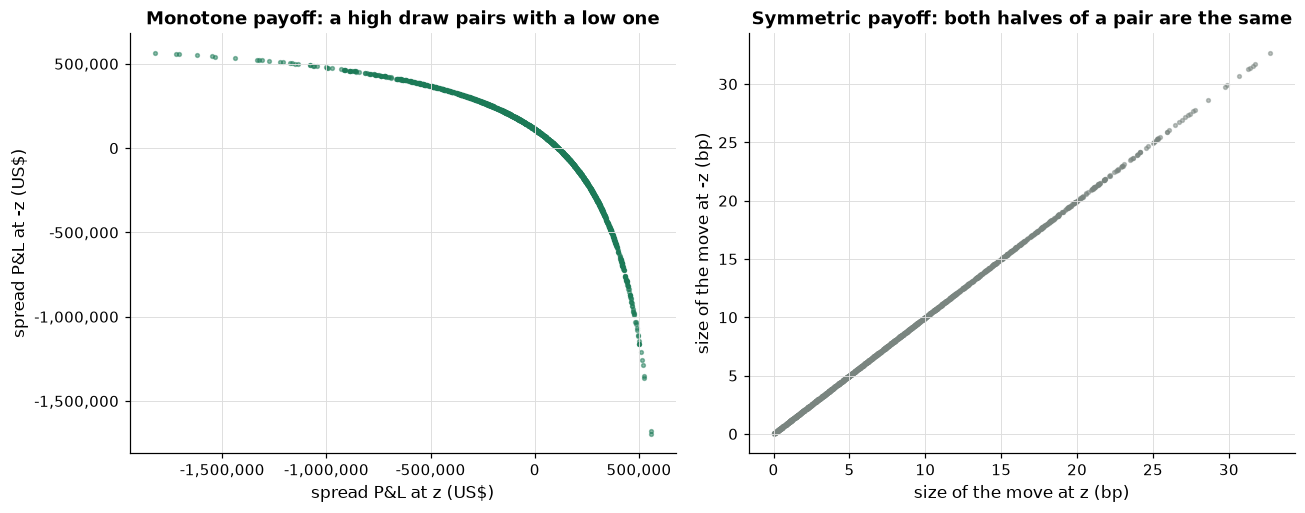

In [34]:
# the first 2,000 pairs: the payoff at z across, the payoff at -z up
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
z = z_pairs[:2_000]
axes[0].scatter(spread_pnl(z), spread_pnl(-z), s=6, color=plotkit.GREEN, alpha=0.5)
axes[0].set_xlabel("spread P&L at z (US$)")
axes[0].set_ylabel("spread P&L at -z (US$)")
axes[0].set_title("Monotone payoff: a high draw pairs with a low one")
axes[1].scatter(move_size_bp(z), move_size_bp(-z), s=6, color=plotkit.GREY, alpha=0.5)
axes[1].set_xlabel("size of the move at z (bp)")
axes[1].set_ylabel("size of the move at -z (bp)")
axes[1].set_title("Symmetric payoff: both halves of a pair are the same")
for ax in axes:
    ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
fig.tight_layout()
plt.show()

* How to read it: on the left the pairs fall along a curve going down, so in each pair one payoff is above the mean and the other below, and their average is calm. The curve bends because a spread move is lognormal: a widening loses more than the matching tightening gains, and that bend is the part of the noise the pairing cannot cancel (Exercise 4). On the right every pair sits on the diagonal: the two halves are copies. Before using antithetic draws, ask whether the payoff moves one way as the draw rises.

## 1.7 How Many Trials?

**How it works.** Fix the precision first: "within a half-width h of the true mean, with 95 percent confidence". The standard error after n trials is sd over root n, and the interval is 1.96 standard errors wide on each side, so n = (1.96 x sd / h) squared. The settings are the half-width, the confidence, and the standard deviation of one trial, which a small pilot run can measure. What comes out is a number of trials to run before the result is worth reading. The 1.96 relies on the mean being close to normal, which needs enough of the rare events in each run.

Q. How many trials put the mean within 20, 10, and 5 percent of the expected loss, at 90, 95, and 99 percent confidence?

In [35]:
# trials for a half-width of 20, 10, and 5 percent of the expected loss, at three confidence levels
needed = pd.DataFrame({
    f"{confidence:.0%} confidence": {f"{share:.0%} of the expected loss": riskkit.trials_needed(sd_one_trial, share * expected_loss, confidence)
                                     for share in [0.20, 0.10, 0.05]}
    for confidence in [0.90, 0.95, 0.99]
})
needed.index.name = "half-width"
print(needed.to_string())

                          90% confidence  95% confidence  99% confidence
half-width                                                              
20% of the expected loss            3315            4706            8128
10% of the expected loss           13258           18824           32511
5% of the expected loss            53029           75293          130044


In [36]:
plotkit.styled(needed, [], "Trials needed for one bond's mean loss: half-width as a share of the expected loss, by confidence",
               fmt="{:,.0f}")

,90% confidence,95% confidence,99% confidence
half-width,,,
20% of the expected loss,"3,315","4,706","8,128"
10% of the expected loss,"13,258","18,824","32,511"
5% of the expected loss,"53,029","75,293","130,044"


* Within 10 percent at 95 percent confidence takes 18,824 trials; within 5 percent takes 75,293, four times as many. A rare loss with a spread 7 times its mean is expensive to pin down, and a portfolio of rare losses (day 3) more so.

Q. Check the 95 percent interval: run 2,000 separate experiments at 500 trials and at 5,000 trials, and count how often the interval holds the exact expected loss.

In [37]:
# 2,000 separate experiments at each size: in how many does the 95 percent interval hold the exact expected loss?
rng = np.random.default_rng(SEED)
coverage_rows, intervals = [], {}
for n in [500, 5_000]:
    hits, kept = 0, []
    for experiment in range(2_000):
        sample = np.where(rng.random(n) < PD, LGD * EAD, 0.0)
        mean, se = riskkit.mc_mean(sample)
        low, high = mean - 1.96 * se, mean + 1.96 * se
        hits += low <= expected_loss <= high
        kept.append((low, high))
    intervals[n] = np.array(kept)
    coverage_rows.append({"trials per experiment": n, "defaults per experiment, on average": n * PD,
                          "share of intervals holding the exact": hits / 2_000})
coverage = pd.DataFrame(coverage_rows).set_index("trials per experiment")
print(coverage.to_string())

                       defaults per experiment, on average  share of intervals holding the exact
trials per experiment                                                                           
500                                                   10.0                                0.9270
5000                                                 100.0                                0.9545


In [38]:
plotkit.styled(coverage, ["share of intervals holding the exact"], "2,000 experiments at each size: how often the 95 "
               "percent interval held the exact expected loss", fmt="{:.3f}")

,"defaults per experiment, on average",share of intervals holding the exact
trials per experiment,,
500,10.000,0.927
5000,100.000,0.955


* At 5,000 trials the interval held the truth in 95.5% of experiments: as promised. At 500 trials, 92.7%. With only 10 defaults expected per experiment, the count of defaults is lumpy and the mean is not yet close to normal, so the 1.96 rule overstates its own precision.

Q. Draw the first 60 intervals at each size, with the misses marked.

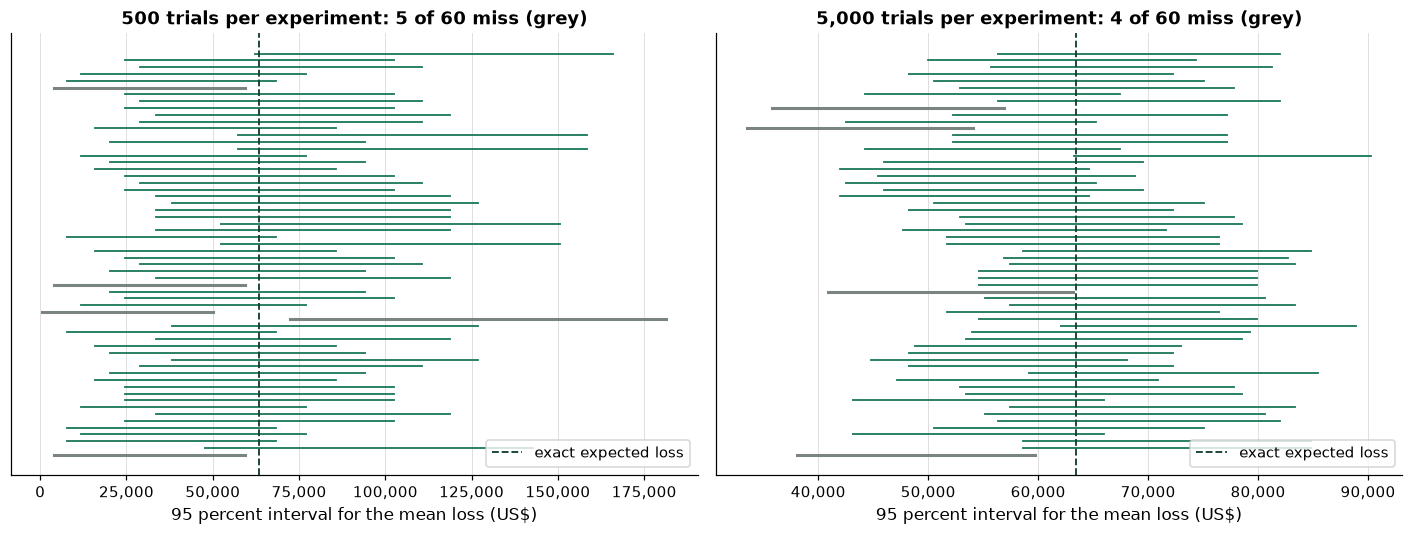

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, n in zip(axes, [500, 5_000]):
    shown = intervals[n][:60]
    for row, (low, high) in enumerate(shown):
        missed = not (low <= expected_loss <= high)
        ax.plot([low, high], [row, row], color=plotkit.GREY if missed else plotkit.GREEN, linewidth=2 if missed else 1.2)
    ax.axvline(expected_loss, color=plotkit.GREEN_DARK, linestyle="--", linewidth=1.2, label="exact expected loss")
    misses = int(sum(not (low <= expected_loss <= high) for low, high in shown))
    ax.set_title(f"{n:,} trials per experiment: {misses} of 60 miss (grey)")
    ax.set_xlabel("95 percent interval for the mean loss (US$)")
    ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
    ax.set_yticks([])
    ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

* How to read it: one line per experiment, its interval from left to right; grey lines miss the dashed truth. Mind the two x axes: at 5,000 trials the intervals are about three times narrower (the square root of 10). Sixty intervals are too few to measure a miss rate, so the counts in the two titles say little; the 2,000 experiments in the table above are the measure. More trials buy narrower intervals, and intervals whose 95 percent you can believe.

## A Story: Where the Name Came From

In the spring of 1946, Los Alamos reviewed a set of calculations it had run on the ENIAC, the first electronic computer. Stanislaw Ulam, a mathematician who attended the review of those results, knew that statistical sampling had been dropped as a technique because the arithmetic took too long by hand, and saw that a machine like the ENIAC could do it. John von Neumann saw the point of Ulam's suggestion and, on March 11, 1947, sent a handwritten letter to Robert Richtmyer outlining a statistical approach to neutron diffusion in fissionable material. Nicholas Metropolis later wrote that he suggested the name, "not unrelated to the fact that Stan had an uncle who would borrow money from relatives because he 'just had to go to Monte Carlo.'" Metropolis and Ulam published "The Monte Carlo Method" in the *Journal of the American Statistical Association* in September 1949.

The point for a risk desk: the method was invented for a problem with too many interacting random parts to solve on paper. A portfolio's credit loss is that kind of problem.

Sources: N. Metropolis, "The Beginning of the Monte Carlo Method", *Los Alamos Science*, Special Issue 1987, pages 125 to 130, https://mcnpx.lanl.gov/pdf_files/Article_1987_LAS_Metropolis_125--130.pdf ; N. Metropolis and S. Ulam, "The Monte Carlo Method", *Journal of the American Statistical Association* 44 (247), 1949, pages 335 to 341.

## Excel Side by Side

Excel runs a Monte Carlo with two functions and one feature: `RAND()` for a uniform draw, an inverse distribution function such as `NORM.S.INV` to turn it into a normal draw, and a one-variable Data Table to repeat the sheet once per row. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-22). To compare with Python exactly, the check pasted the notebook's first 1,000 uniform draws from section 1.1 into A2:A1001 in place of `RAND()`, with PD in E1, LGD in E2, and EAD in E3.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Expected loss | `PD * LGD * EAD` | `=E1*E2*E3` | US$63,450 |
| A uniform draw | `rng.random()` | `=RAND()` | a new value on every recalculation |
| A normal draw from a uniform | `norm.ppf(u)` | `=NORM.S.INV(A2)` | equal within 1e-9 on 1,000 rows |
| The antithetic draw | `-z` | `=NORM.S.INV(1-A2)` | equal within 1e-9 |
| A year's loss | `np.where(u < PD, LGD * EAD, 0.0)` | `=IF(A2<$E$1,$E$2*$E$3,0)` | equal on every row |
| The mean and its standard error | `riskkit.mc_mean(loss)` | `=AVERAGE(C2:C1001)` and `=STDEV.S(C2:C1001)/SQRT(COUNT(C2:C1001))` | US$63,450 and US$14,052 |
| k defaults among 50 | `binom.pmf(k, 50, PD)` | `=BINOM.DIST(G2,50,$E$1,FALSE)` | equal within 1e-12 for k = 0 to 7 |
| At least 4 defaults | `binom.sf(3, 50, PD)` | `=1-BINOM.DIST(3,50,E1,TRUE)` | 0.017758 |
| Trials for 10 percent at 95 percent | `riskkit.trials_needed(sd, 0.1 * EL)` | `=ROUNDUP((NORM.S.INV(0.975)*E5/(0.1*E4))^2,0)` | 18,824 |

**Draws.** `RAND()` returns a uniform number from 0 up to 1, and a new one every time the sheet recalculates (press F9): Excel's simulation has no seed, so its numbers change on every recalculation, where a seeded Python run gives the same numbers every time. `NORM.S.INV(RAND())` is the middle panel of section 1.2: the inverse transform. `NORM.S.INV(1-A2)` is the mirror of `NORM.S.INV(A2)`, which is how an antithetic draw is made in Excel.

**Trials.** One year is one row: `IF(A2<$E$1,$E$2*$E$3,0)` is the loss, filled down. `AVERAGE` is the Monte Carlo mean, and `STDEV.S` over `SQRT(COUNT(...))` its standard error, which is `mc_mean`. To repeat a whole sheet many times instead, a one-variable Data Table (Data, What-If Analysis, Data Table) with its column input pointing at an empty cell recalculates the sheet once per row; the check built one of 1,000 rows and every row held a fresh trial.

**Exact answers.** `BINOM.DIST(k,50,0.02,FALSE)` is the chance of exactly k defaults, the binomial column of section 1.5; with `TRUE` it is the chance of k or fewer, so one minus it at 3 is the chance of at least 4. The trial count of section 1.7 is one formula with `ROUNDUP` for the ceiling.

In [40]:
# Excel's results, from the course's Excel check, beside Python's
excel_side = pd.DataFrame({
    "Excel": [63449.55, 63449.55, 14052.184465526194, 0.01775808069797158, 18824],
    "Python": [expected_loss, riskkit.mc_mean(losses[:1_000])[0], riskkit.mc_mean(losses[:1_000])[1],
               p4_exact, riskkit.trials_needed(sd_one_trial, 0.1 * expected_loss, 0.95)],
}, index=pd.Index(["expected loss (US$)", "mean of the first 1,000 years (US$)", "its standard error (US$)",
                    "chance of at least 4 defaults among 50", "trials for 10 percent at 95 percent"], name="Check"))
excel_side["equal within 1e-9"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-9
plotkit.styled(excel_side, [], "Excel beside Python on today's bond: the exact answers and the first 1,000 simulated years",
               fmt="{:,.6f}")

,Excel,Python,equal within 1e-9
Check,,,
expected loss (US$),"63,449.550000","63,449.550000",True
"mean of the first 1,000 years (US$)","63,449.550000","63,449.550000",True
its standard error (US$),"14,052.184466","14,052.184466",True
chance of at least 4 defaults among 50,0.017758,0.017758,True
trials for 10 percent at 95 percent,"18,824.000000","18,824.000000",True


* Every value is equal within 1e-9. `NORM.S.INV` matched scipy's `norm.ppf` on all 1,000 draws within 4.7e-15, and every year's loss matched exactly.

## Save the Day with Git

Today's Git step starts the course's repository in the work folder and commits the new module with its tests.

Q. Start a repository in the work folder.

In [41]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [42]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5c_01_ef88b9nr and nowhere else


Q. Tell Git which files never to track, then see what it would track.

In [43]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [44]:
# ?? marks a file Git does not track yet
!git -C "{work}" status --short

?? .gitignore
?? holdings.csv
?? mlkit.py
?? plotkit.py
?? ratings.csv
?? riskkit.py
?? test_riskkit.py


* The book and the rating scale are the course's data and `plotkit.py` the course's helpers: they stay untracked. The commit takes the code.

Q. Commit the code: `mlkit.py`, `riskkit.py`, and its tests.

In [45]:
!git -C "{work}" add .gitignore mlkit.py riskkit.py test_riskkit.py
!git -C "{work}" commit -q -m "Day 1: riskkit with mc_mean, trials_needed, and antithetic_normals"
!git -C "{work}" log --oneline --stat

500c8f4 Day 1: riskkit with mc_mean, trials_needed, and antithetic_normals


 .gitignore      |   3 +
 mlkit.py        | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 riskkit.py      |  63 +++++++
 test_riskkit.py |  55 ++++++
 4 files changed, 689 insertions(+)


## Bring It Home

Start `riskkit.py` in your own `my_bondmath` folder, beside `mlkit.py`, `ensemblekit.py`, and `tskit.py`. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Create `riskkit.py` and paste the code of today's two `riskkit.py` cells (sections 1.3 and 1.6), without their first lines, one after the other. Do the same for the two `test_riskkit.py` cells in a new `test_riskkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_riskkit.py
```

The last line says `6 passed`.

**Step 4.** Commit.

```powershell
git add riskkit.py test_riskkit.py
git commit -m "Day 1: riskkit with mc_mean, trials_needed, and antithetic_normals"
```

## You Can Now

* Simulate a credit loss year by year and compare the mean with the exact expected loss, PD x LGD x EAD.
* Seed numpy's generator, reproduce every draw, and split one seed into independent streams with `spawn`.
* Report a Monte Carlo mean with its standard error (`mc_mean`), and say why a hundred times the trials buys ten times the precision.
* Draw from the normal, Student's t, lognormal, and beta, and say which setting sets each tail.
* Check a simulated count of defaults against the binomial, and say what independence assumes.
* Use antithetic pairs (`antithetic_normals`) on a payoff that moves one way with the draw, and not on a symmetric one.
* Work out the trials a stated precision needs (`trials_needed`), and know when the 95 percent interval is not yet 95 percent.

Next, day 2: historical simulation and VaR, the book's daily P&L had the past days repeated.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the book, picks today's bond, sets the inputs, simulates the 100,000 years of section 1.1, defines the two payoffs of section 1.6, and defines `check`, a small function that marks your answers.

In [46]:
from scipy.stats import binom, norm

# the book and the rating scale: every issuer and CUSIP in both files is invented
book = pd.read_csv("holdings.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")
book["bucket"] = book["rating"].map(ratings["bucket"])

# the bond for today: the book's largest BB holding by market value
bond = book[book["bucket"] == "BB"].sort_values("market_value", ascending=False).iloc[0]
print(f"{bond['issuer']} ({bond['cusip']}), rated {bond['rating']}: market value US${bond['market_value']:,.0f}")

# two inputs chosen for the lesson, not an estimate for this or any issuer
PD = 0.02     # the chance of default within one year: 2 percent
LGD = 0.60    # the share of the exposure lost if it defaults: 60 percent
EAD = float(bond["market_value"])   # the exposure at default, in US$: today's market value

# the exact answers, which the simulation has to find on its own
expected_loss = PD * LGD * EAD
sd_one_trial = np.sqrt(PD * (1 - PD)) * LGD * EAD
print(f"expected loss: US${expected_loss:,.2f}")
print(f"standard deviation of one year's loss: US${sd_one_trial:,.2f}")

rng = np.random.default_rng(SEED)
u_100k = rng.random(100_000)
losses = np.where(u_100k < PD, LGD * EAD, 0.0)

# a spread move for the same bond over a year: its OAS times a lognormal relative change with mean 1
# SIGMA is an input chosen for the lesson; the move's mean is 0 bp exactly, so the true mean P&L is US$0
SIGMA = 0.40
OAS = float(bond["oas"])
SPREAD_DURATION = float(bond["spread_duration"])


def spread_pnl(z):
    """P&L in US$ of the bond for standard normal draws z: minus spread duration x market value x the move in bp."""
    move_bp = OAS * (np.exp(SIGMA * z - SIGMA ** 2 / 2) - 1)
    return -SPREAD_DURATION * EAD * move_bp / 10_000


def move_size_bp(z):
    """The size of a rate move in bp for standard normal draws z, with a 10 bp standard deviation: the same for z and -z."""
    return np.abs(10 * z)
print(f"OAS {OAS:.0f} bp, spread duration {SPREAD_DURATION:.3f}, sigma {SIGMA}")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

Lorvebran Paper (99076YAC0), rated BB: market value US$5,287,462
expected loss: US$63,449.55
standard deviation of one year's loss: US$444,146.85
OAS 229 bp, spread duration 6.240, sigma 0.4


### Exercise 1

Q. Among 50 independent bonds, each with a 2 percent default chance, what is the exact chance of at least 3 defaults in a year? Use `binom.sf`, which gives the chance of more than k. Store it in **ex1_at_least_3**, then check it with a simulation of 100,000 years.

In [47]:
ex1_at_least_3 = ...

In [48]:
check("Exercise 1 at least 3 defaults among 50", ex1_at_least_3, 0.0784277483509691)

Exercise 1 at least 3 defaults among 50: not attempted yet


### Exercise 2

Q. How many trials put the mean loss within 5 percent of the expected loss at 99 percent confidence? Store the count in **ex2_trials**. How many times the 95 percent count of section 1.7 is it?

In [49]:
ex2_trials = ...

In [50]:
check("Exercise 2 trials for 5 percent at 99 percent", ex2_trials, 130044)

Exercise 2 trials for 5 percent at 99 percent: not attempted yet


### Exercise 3

Q. Add a function to your module. `running_mean(draws)` returns the mean of the first 1, 2, ..., n draws, and refuses an empty array or a NaN with `ValueError`. Write the docstring first. Add `test_running_mean_hand`, which checks `[2.0, 4.0, 9.0]` gives `[2.0, 3.0, 5.0]` and checks the refusal of an empty array. Run pytest, reload the module, and store the running mean of `losses` after 1,000 years, `riskkit.running_mean(losses)[999]`, in **ex3_after_1000**.

Write the function in the cell that starts with `%%writefile -a riskkit.py` and the test in the one that starts with `%%writefile -a test_riskkit.py`, and run each of those cells once.

In [51]:
%%writefile -a riskkit.py


# Exercise 3: write running_mean(draws) below this line

Appending to riskkit.py


In [52]:
%%writefile -a test_riskkit.py


# Exercise 3: write test_running_mean_hand() below this line

Appending to test_riskkit.py


In [53]:
# run pytest, reload the module, then use your function
ex3_after_1000 = ...

In [54]:
check("Exercise 3 running mean after 1,000 years", ex3_after_1000, 63449.55)

Exercise 3 running mean after 1,000 years: not attempted yet


### Exercise 4

Q. Sweep the spread move's sigma: 0.1, 0.4, and 0.8. For each, compute the variance ratio of plain over antithetic draws on the spread P&L, with the same 20,000-draw budget and the same two spawned generators as section 1.6. Store the ratio at sigma 0.8 in **ex4_ratio_08**. Why does the gain shrink as sigma grows?

In [55]:
ex4_ratio_08 = ...

In [56]:
check("Exercise 4 variance ratio at sigma 0.8", ex4_ratio_08, 2.451352073022219)

Exercise 4 variance ratio at sigma 0.8: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that simulates a bond's credit loss, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Simulate n independent years of one bond's credit loss.

    rng is a numpy Generator; each year draws its own uniform number from it, and the bond defaults that year
    when the number is below pd. A default loses lgd x ead US$; a year without one loses nothing.
    Returns an array of n losses in US$.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns an array of the right length, and contains one bug.

In [57]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def simulate_losses(rng, n, pd, lgd, ead):
    """Simulate n independent years of one bond's credit loss.

    rng is a numpy Generator; each year draws its own uniform number from it, and the bond defaults that year
    when the number is below pd. A default loses lgd x ead US$; a year without one loses nothing.
    Returns an array of n losses in US$.
    """
    losses = np.zeros(n)
    for year in range(n):
        # a generator seeded with 42 so the result can be reproduced
        draw = np.random.default_rng(42).random()
        if draw < pd:
            losses[year] = lgd * ead
    return losses

Q. Before you run the next cell: in 1,000 simulated years with a 2 percent default chance, about how many defaults should there be? How many does the function give?

In [58]:
sim = simulate_losses(np.random.default_rng(SEED), 1_000, PD, LGD, EAD)
print(f"years with a default: {int((sim > 0).sum())} of {len(sim)}; distinct losses: {np.unique(sim).tolist()}")

years with a default: 0 of 1000; distinct losses: [0.0]


Q. Test the function against its docstring before you trust it: some years default and some do not, and the mean lands near the exact expected loss.

In [59]:
# the test, written from the docstring before the code is trusted
sim = simulate_losses(np.random.default_rng(SEED), 20_000, PD, LGD, EAD)
mean, se = riskkit.mc_mean(sim)
# independent years: some default and some do not, and the mean lands near the exact expected loss
assert 0 < int((sim > 0).sum()) < len(sim), f"{int((sim > 0).sum())} of {len(sim)} years defaulted: every year drew the same number"
assert abs(mean - expected_loss) < 4 * se, "the mean is far from the exact expected loss"
print(f"mean US${mean:,.0f} against the exact US${expected_loss:,.0f}, standard error US${se:,.0f}")

AssertionError: 0 of 20000 years defaulted: every year drew the same number

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's mean over 20,000 years, `float(simulate_losses(np.random.default_rng(SEED), 20_000, PD, LGD, EAD).mean())`, in **ex5_mean**.

In [60]:
# fix the function above and run the test again, then store the answer
ex5_mean = ...

In [61]:
check("Exercise 5 mean of the fixed function", ex5_mean, 63608.173875)

Exercise 5 mean of the fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```